# Mito vs Viability Pairwise BRICS Enrichment

Three pairwise comparisons using Fisher's exact test + BH FDR, BRICS decomposition.

| Analysis | Foreground | Background |
|----------|-----------|------------|
| A1 | Both active (292) | Both inactive (3,196) |
| A2 | Both active (292) | Mito active, viability inactive (680) |
| A3 | Mito active, viability inactive (680) | Both inactive (3,196) |

In [44]:
import pandas as pd
import numpy as np
import re
import warnings
import json as _json
import urllib.request, urllib.parse, time
from collections import Counter, defaultdict, OrderedDict

import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

from rdkit import Chem
from rdkit.Chem import BRICS, Draw
from IPython.display import display, SVG

warnings.filterwarnings('ignore')

BASE     = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
MITO_VIB = BASE + 'results/mito_viability_comparisons/'
FIGS     = BASE + 'figures/'
import os; os.makedirs(FIGS, exist_ok=True)

# ── SMILES loader ─────────────────────────────────────────────────────────────
def load_cid_smiles(path):
    df = pd.read_csv(path,
                     usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
                     low_memory=False)
    df = df.dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    df = df.drop_duplicates('PUBCHEM_CID').reset_index(drop=True)
    return df[['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES']].rename(
        columns={'PUBCHEM_EXT_DATASOURCE_SMILES': 'smiles'})

# ── BRICS helpers ─────────────────────────────────────────────────────────────
def brics_frags(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return frozenset(BRICS.BRICSDecompose(mol)) if mol else frozenset()

def clean_frag(frag_smi):
    return re.sub(r'\[\d+\*\]', '[H]', frag_smi)

# ── Fisher enrichment (one-tailed, BH FDR) ───────────────────────────────────
def fisher_enrichment(fg_sets, bg_sets, label_a='A', label_b='B',
                      min_count=3, fdr_alpha=0.05):
    na, nb = len(fg_sets), len(bg_sets)
    all_frags = set().union(*fg_sets, *bg_sets)
    rows = []
    for frag in all_frags:
        a = sum(1 for fs in fg_sets if frag in fs)
        c = sum(1 for fs in bg_sets if frag in fs)
        if a < min_count:
            continue
        b, d = na - a, nb - c
        _, pval = fisher_exact([[a, b], [c, d]], alternative='greater')
        or_ = (a * d) / (b * c) if b * c > 0 else float('inf')
        rows.append({'fragment': frag,
                     f'n_{label_a}': a, f'pct_{label_a}': 100*a/na,
                     f'n_{label_b}': c, f'pct_{label_b}': 100*c/nb,
                     'odds_ratio': or_, 'pvalue': pval})
    if not rows:
        return pd.DataFrame()
    df = pd.DataFrame(rows)
    _, padj, _, _ = multipletests(df['pvalue'], method='fdr_bh')
    df['padj'] = padj
    return df[df['padj'] < fdr_alpha].sort_values('padj').reset_index(drop=True)

# ── PubChem name lookup ───────────────────────────────────────────────────────
def pubchem_name(smiles_clean, timeout=10):
    mol = Chem.MolFromSmiles(smiles_clean)
    if mol is None:
        return None
    enc = urllib.parse.quote(Chem.MolToSmiles(mol), safe='')
    base = f'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/{enc}'
    try:
        with urllib.request.urlopen(f'{base}/property/IUPACName,Title/JSON', timeout=timeout) as r:
            p = _json.loads(r.read())['PropertyTable']['Properties'][0]
        return p.get('Title') or p.get('IUPACName')
    except Exception:
        pass
    try:
        with urllib.request.urlopen(f'{base}/synonyms/JSON', timeout=timeout) as r:
            syns = _json.loads(r.read())['InformationList']['Information'][0].get('Synonym', [])
        return syns[0] if syns else None
    except Exception:
        return None

# ── Structural family assignment (ring-count first, then SMARTS) ──────────────
_PATT = {k: Chem.MolFromSmarts(v) for k, v in {
    'phenol':     'c-[OH]',
    'heteroar':   '[n]',
    'ring_o':     '[O;R]',
    'halogen':    '[Cl,Br]',
    'carbonyl':   '[CX3](=O)',
    'nitroar':    '[c]-[N+](=O)[O-]',
    'lipophilic': '[CX4;!$([CX4]~[!#6])]',
    'phos':       '[P,Sn,F]',
    'nitrogen':   '[NX3,NX4+]',
}.items()}

def assign_family(brics_smi):
    mol = Chem.MolFromSmiles(clean_frag(brics_smi))
    if mol is None:
        return 'Other'
    ri      = mol.GetRingInfo()
    n_rings = ri.NumRings()
    is_arom = all(mol.GetAtomWithIdx(i).GetIsAromatic()
                  for ring in ri.AtomRings() for i in ring) if n_rings > 0 else False
    # Polycyclic (>=3 rings) OR bicyclic non-aromatic (decalin, anthracycline)
    if n_rings >= 3 or (n_rings == 2 and not is_arom):
        return 'Complex ring / sugar'
    # Ring oxygen — single-ring sugars / pyrans
    if mol.HasSubstructMatch(_PATT['ring_o']):
        return 'Complex ring / sugar'
    # Heteroaromatic (benzimidazole, pyridine) — before phenol check
    if mol.HasSubstructMatch(_PATT['heteroar']):
        return 'Heteroaromatic family'
    # Phenolic OH
    if mol.HasSubstructMatch(_PATT['phenol']):
        return 'Phenolic family'
    # Halogenated (Cl/Br)
    if mol.HasSubstructMatch(_PATT['halogen']):
        return 'Halogenated family'
    # Carbonyl (aldehyde, ketone)
    if mol.HasSubstructMatch(_PATT['carbonyl']):
        return 'Carbonyl family'
    # Nitroaromatic
    if mol.HasSubstructMatch(_PATT['nitroar']):
        return 'Nitroaromatic family'
    # Lipophilic chain
    if mol.HasSubstructMatch(_PATT['lipophilic']):
        return 'Lipophilic chain family'
    # Organophosphate / organotin / fluorine
    if mol.HasSubstructMatch(_PATT['phos']):
        return 'Organophosphate & halogen'
    # Amines
    if mol.HasSubstructMatch(_PATT['nitrogen']):
        return 'Nitrogen-containing family'
    return 'Other'

# Display order for figure panels
FAMILY_ORDER = [
    'Phenolic family',
    'Complex ring / sugar',
    'Lipophilic chain family',
    'Carbonyl family',
    'Halogenated family',
    'Heteroaromatic family',
    'Nitroaromatic family',
    'Organophosphate & halogen',
    'Nitrogen-containing family',
    'Other',
]

# Manual name overrides for fragments where PubChem lookup fails
MANUAL_NAMES = {
    # Decalin (bicyclic, non-aromatic; PubChem lookup fails for stereoisomers)
    '[7*]C1CCC[C@]2(C)[C@@H]([15*])CC[C@@H]12': 'Methyldecalin',
    # Anthracyclinone aglycone (doxorubicin scaffold; too large for PubChem SMILES lookup)
    '[3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)C(=O)c1c([16*])cccc1C3=O': 'Anthracyclinone',
}

# ── Main pipeline: enrich → name → figure ────────────────────────────────────
def run_analysis(fg_df, bg_df, label_a, label_b, fig_fname, top_n=12,
                 min_count=3, fdr_alpha=0.05):
    print(f'\n=== {label_a} (n={len(fg_df)}) vs {label_b} (n={len(bg_df)}) ===')

    fg_sets = [brics_frags(s) for s in fg_df['smiles']]
    bg_sets = [brics_frags(s) for s in bg_df['smiles']]

    enrich = fisher_enrichment(fg_sets, bg_sets,
                               label_a=label_a, label_b=label_b,
                               min_count=min_count, fdr_alpha=fdr_alpha)
    print(f'Significant fragments: {len(enrich)}')
    if enrich.empty:
        print('No significant fragments found.')
        return enrich

    top = enrich.head(top_n)

    # PubChem names (with manual override fallback)
    print('Fetching PubChem names...')
    frag_names = {}
    for frag in top['fragment']:
        clean = clean_frag(frag)
        if frag in MANUAL_NAMES:
            name = MANUAL_NAMES[frag]
        else:
            name = pubchem_name(clean)
        frag_names[frag] = name if name else clean
        print(f"  {'NOT FOUND' if not name else name:45s}  <- {frag}")
        time.sleep(0.25)

    # Group by family preserving FAMILY_ORDER
    family_buckets = OrderedDict((f, []) for f in FAMILY_ORDER)
    for _, row in top.iterrows():
        frag = row['fragment']
        mol  = Chem.MolFromSmiles(clean_frag(frag))
        if mol is None:
            continue
        name = frag_names.get(frag, clean_frag(frag))
        family_buckets[assign_family(frag)].append((mol, name))

    flat = []   # (mol, name, family, is_first_in_family)
    for fname, entries in family_buckets.items():
        for i, (mol, name) in enumerate(entries):
            flat.append((mol, name, fname, i == 0))

    # Figure: 4 per row, family name above first compound of each family
    NCOLS   = 4
    IMG_W, IMG_H = 520, 400
    n_rows  = (len(flat) + NCOLS - 1) // NCOLS

    def to_rgb(mol, w=IMG_W, h=IMG_H):
        return np.asarray(Draw.MolToImage(mol, size=(w, h)).convert('RGB'))

    fig, axes = plt.subplots(n_rows, NCOLS,
                             figsize=(NCOLS * 5.8, n_rows * 5.8),
                             facecolor='white')
    if n_rows == 1:
        axes = np.array([axes])
    fig.subplots_adjust(hspace=0.45, wspace=0.05,
                        left=0.01, right=0.99, top=0.97, bottom=0.01)

    for i, ax in enumerate(axes.flatten()):
        ax.axis('off')
        if i >= len(flat):
            continue
        mol, name, family, is_first = flat[i]
        ax.imshow(to_rgb(mol), aspect='equal', interpolation='lanczos')
        ax.set_title(name, fontsize=16, pad=5,
                     multialignment='center', linespacing=1.4)
        if is_first:
            ax.text(0.5, 1.32, family,
                    transform=ax.transAxes,
                    fontsize=17, fontweight='bold', fontstyle='italic',
                    ha='center', va='bottom', color='#1A1A2E')

    out = FIGS + fig_fname
    fig.savefig(out, dpi=250, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved -> {out}')
    return enrich

print('Setup complete.')


Setup complete.


In [45]:
# ── Load the three groups ─────────────────────────────────────────────────────
df_both_active   = load_cid_smiles(MITO_VIB + 'mito_and_mito_viability_active.csv')
df_mito_only     = load_cid_smiles(MITO_VIB + 'mito_active_and_mito_viability_inctive.csv')
df_both_inactive = load_cid_smiles(MITO_VIB + 'mito_inactive_and_mito_viability_inactive.csv')

print(f'Both active                        : {len(df_both_active):5d} unique CIDs')
print(f'Mito active, viability inactive    : {len(df_mito_only):5d} unique CIDs')
print(f'Both inactive                      : {len(df_both_inactive):5d} unique CIDs')

Both active                        :   292 unique CIDs
Mito active, viability inactive    :   680 unique CIDs
Both inactive                      :  3196 unique CIDs



=== both_active (n=292) vs both_inactive (n=3196) ===


[16:15:27] WARNING: not removing hydrogen atom without neighbors
[16:15:27] WARNING: not removing hydrogen atom without neighbors
[16:15:28] WARNING: not removing hydrogen atom without neighbors


Significant fragments: 59
Fetching PubChem names...
  Phenol                                         <- [16*]c1ccc(O)cc1
  Dimethylaminium                                <- [5*][N+]([5*])(C)C
  Trifluoromethane                               <- [8*]C(F)(F)F
  Isobutane                                      <- [8*]C(C)(C)C
  Dimethyl phosphorothioate                      <- [3*]OP(=S)(OC)OC
  4-Chlorophenol                                 <- [16*]c1cc(Cl)ccc1O
  Phosphoric Acid                                <- [3*]OP(=O)(O[3*])O[3*]
  2,2,4-Trimethylpentane                         <- [8*]C(C)(C)CC(C)(C)C
  M-Cresol                                       <- [16*]c1cc([16*])c(O)cc1C
  Pyrogallol                                     <- [16*]c1cc(O)c(O)c(O)c1
  Tributylhydroxytin                             <- [3*][O][Sn]([CH2]CCC)([CH2]CCC)[CH2]CCC
  1,3-Dinitrobenzene                             <- [16*]c1cc([N+](=O)[O-])cc([N+](=O)[O-])c1[16*]


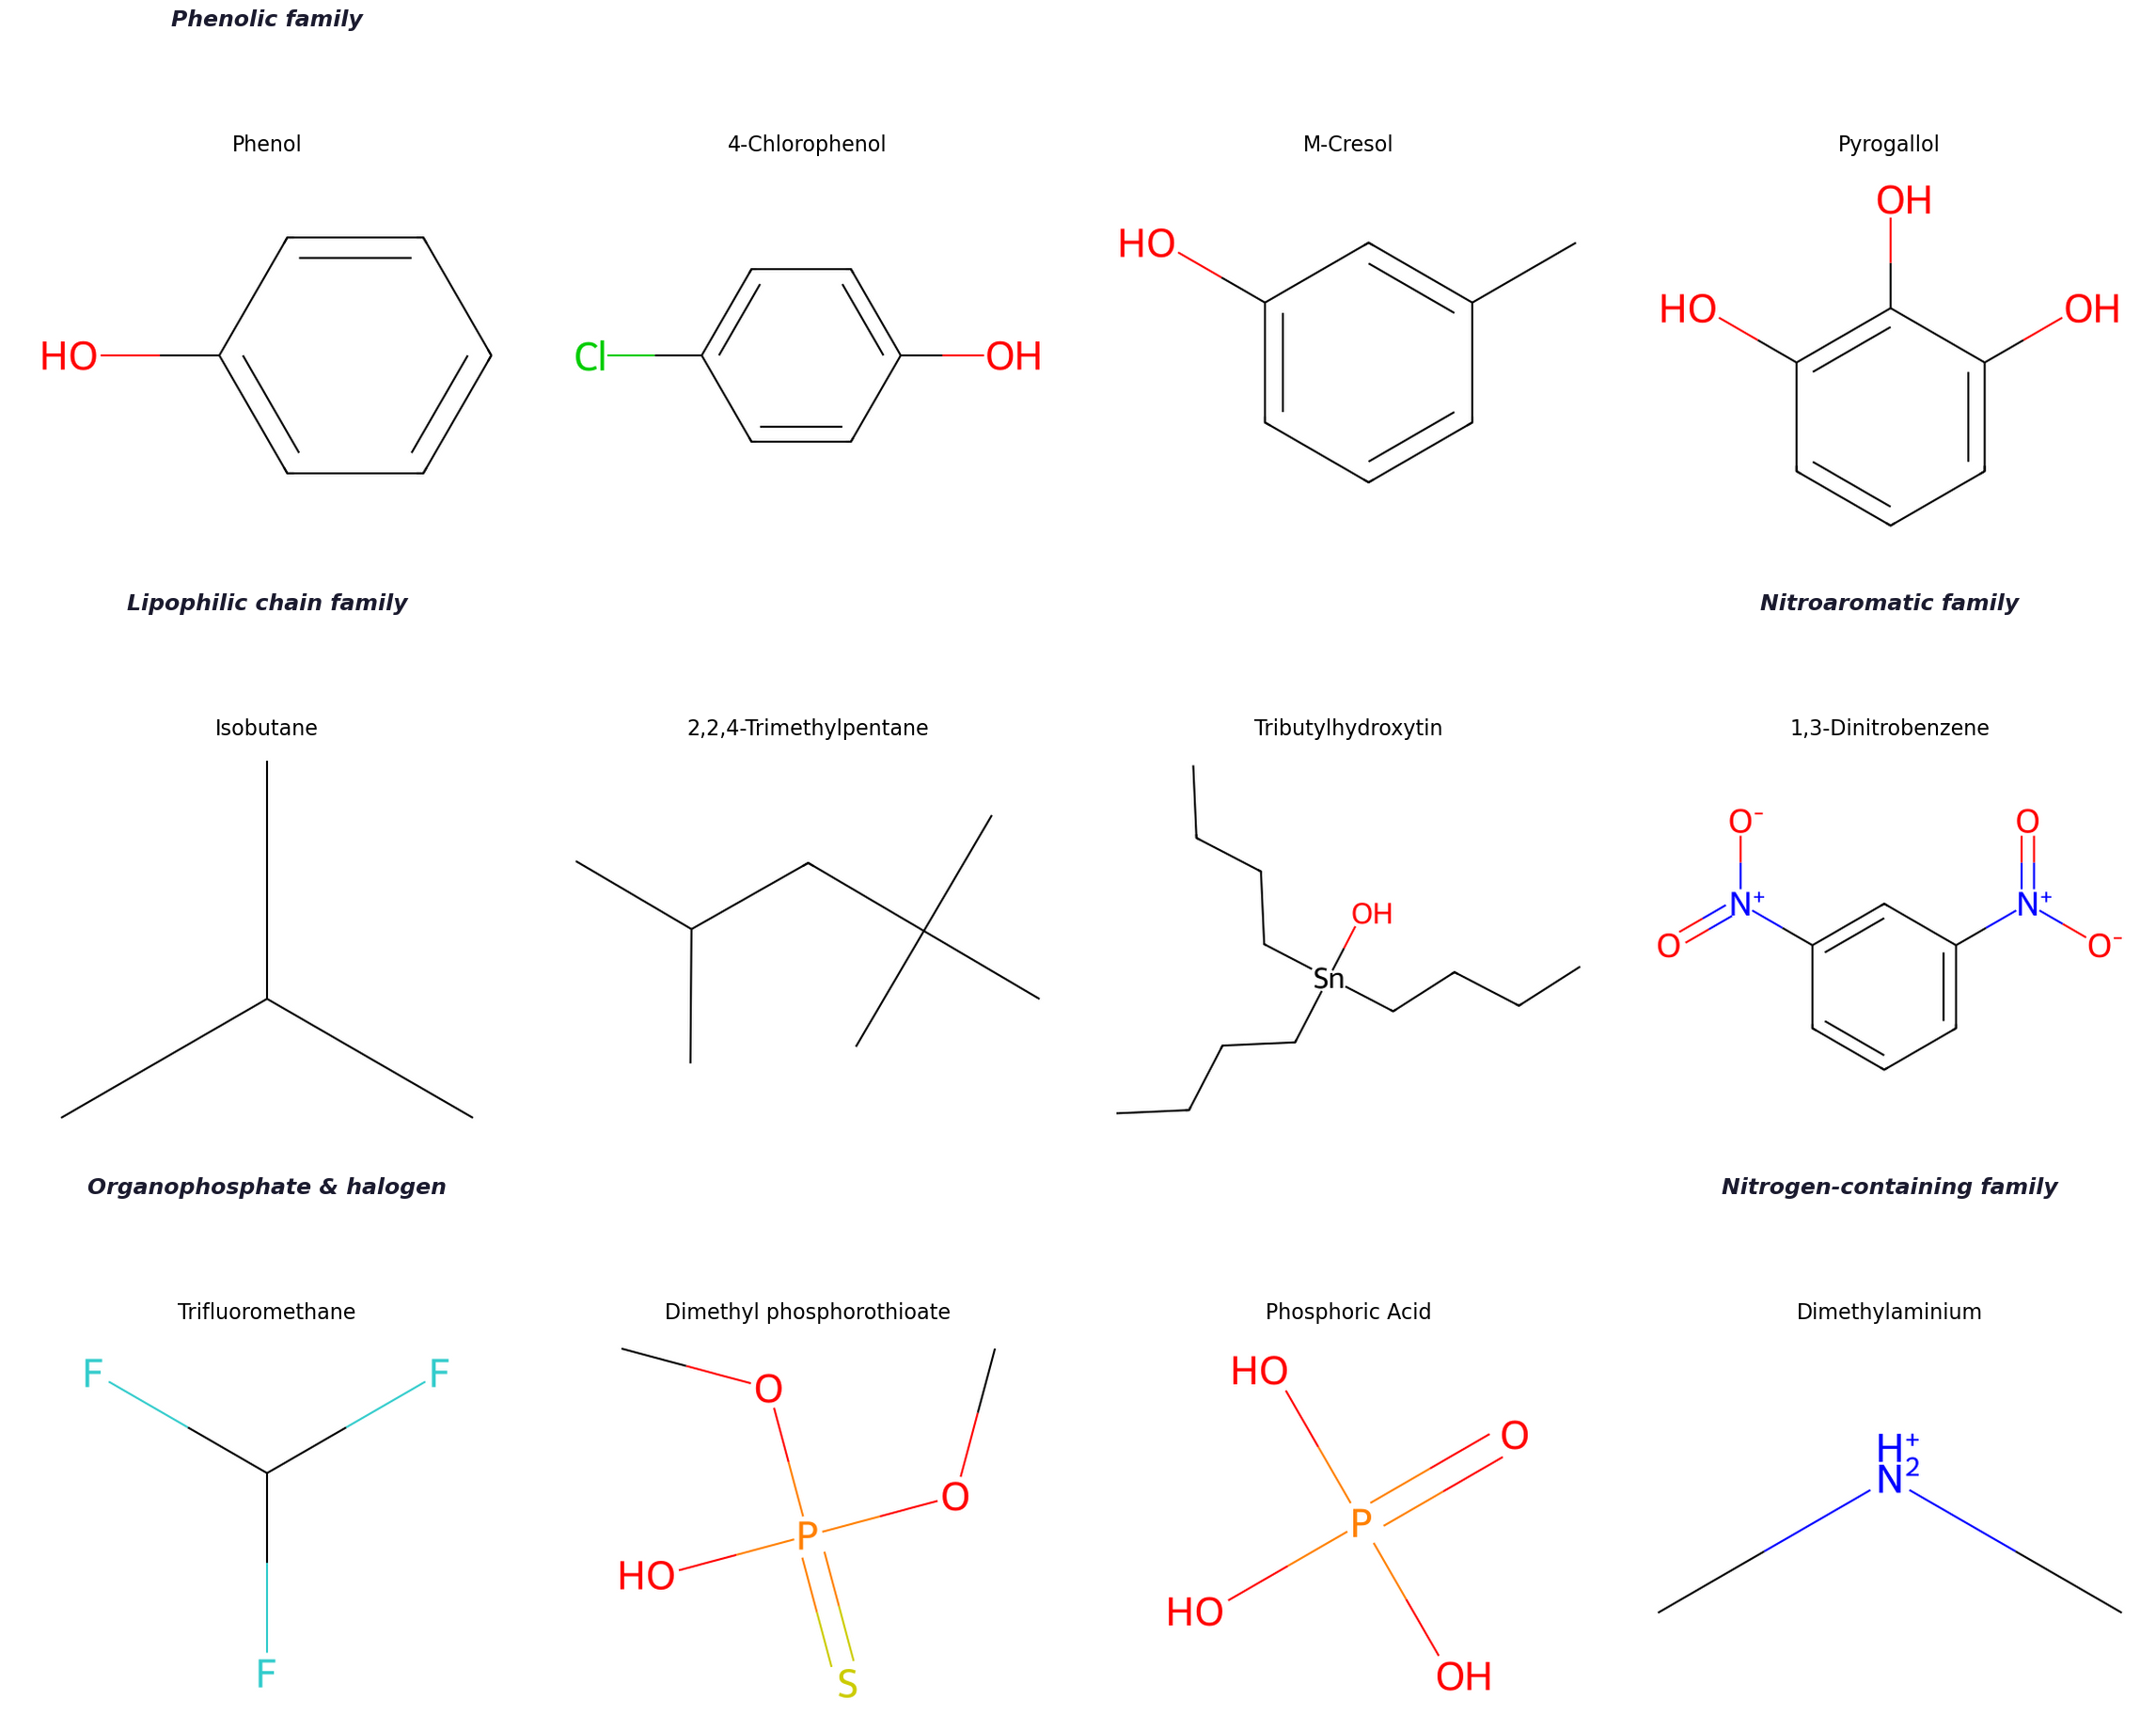

Saved -> /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_mito_both_active_vs_both_inactive.png


In [46]:
# ── Analysis 1: Both Active (292) vs Both Inactive (3,196) ──────────────────
enrich_a1 = run_analysis(
    df_both_active, df_both_inactive,
    label_a='both_active', label_b='both_inactive',
    fig_fname='fig_mito_both_active_vs_both_inactive.png',
    top_n=12, min_count=2, fdr_alpha=0.10
)

In [47]:
# ── Analysis 2: Both Active (292) vs Mito Active / Viability Inactive (680) ──
enrich_a2 = run_analysis(
    df_both_active, df_mito_only,
    label_a='both_active', label_b='mito_only',
    fig_fname='fig_mito_both_active_vs_mito_only.png',
    top_n=12, min_count=2, fdr_alpha=0.10
)


=== both_active (n=292) vs mito_only (n=680) ===


[16:16:08] WARNING: not removing hydrogen atom without neighbors
[16:16:08] WARNING: not removing hydrogen atom without neighbors


Significant fragments: 0
No significant fragments found.



=== mito_only (n=680) vs both_inactive (n=3196) ===


[16:16:12] WARNING: not removing hydrogen atom without neighbors


Significant fragments: 48
Fetching PubChem names...
  Phenol                                         <- [16*]c1ccc(O)cc1
  Ethane                                         <- [7*]CC[7*]
  (2R,4S)-2-methyltetrahydropyran-4-ol           <- [13*][C@H]1C[C@H](O)[C@H]([15*])[C@@H](C)O1
  Isobutane                                      <- [8*]C(C)(C)C
  Formaldehyde                                   <- [6*]C([6*])=O
  (2S,3S,4S)-4-amino-2-methyloxan-3-ol           <- [13*][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1
  Anthracyclinone                                <- [3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)C(=O)c1c([16*])cccc1C3=O
  Decane                                         <- [8*]CCCCCCCCCC
  Chloroacetaldehyde                             <- [6*]C(=O)CCl
  Methyldecalin                                  <- [7*]C1CCC[C@]2(C)[C@@H]([15*])CC[C@@H]12
  Benzimidazole                                  <- [14*]c1nc2ccc([16*])cc2[nH]1
  Methyl Ethyl Ketone                            <- [8*]C([8*])CC(C)=

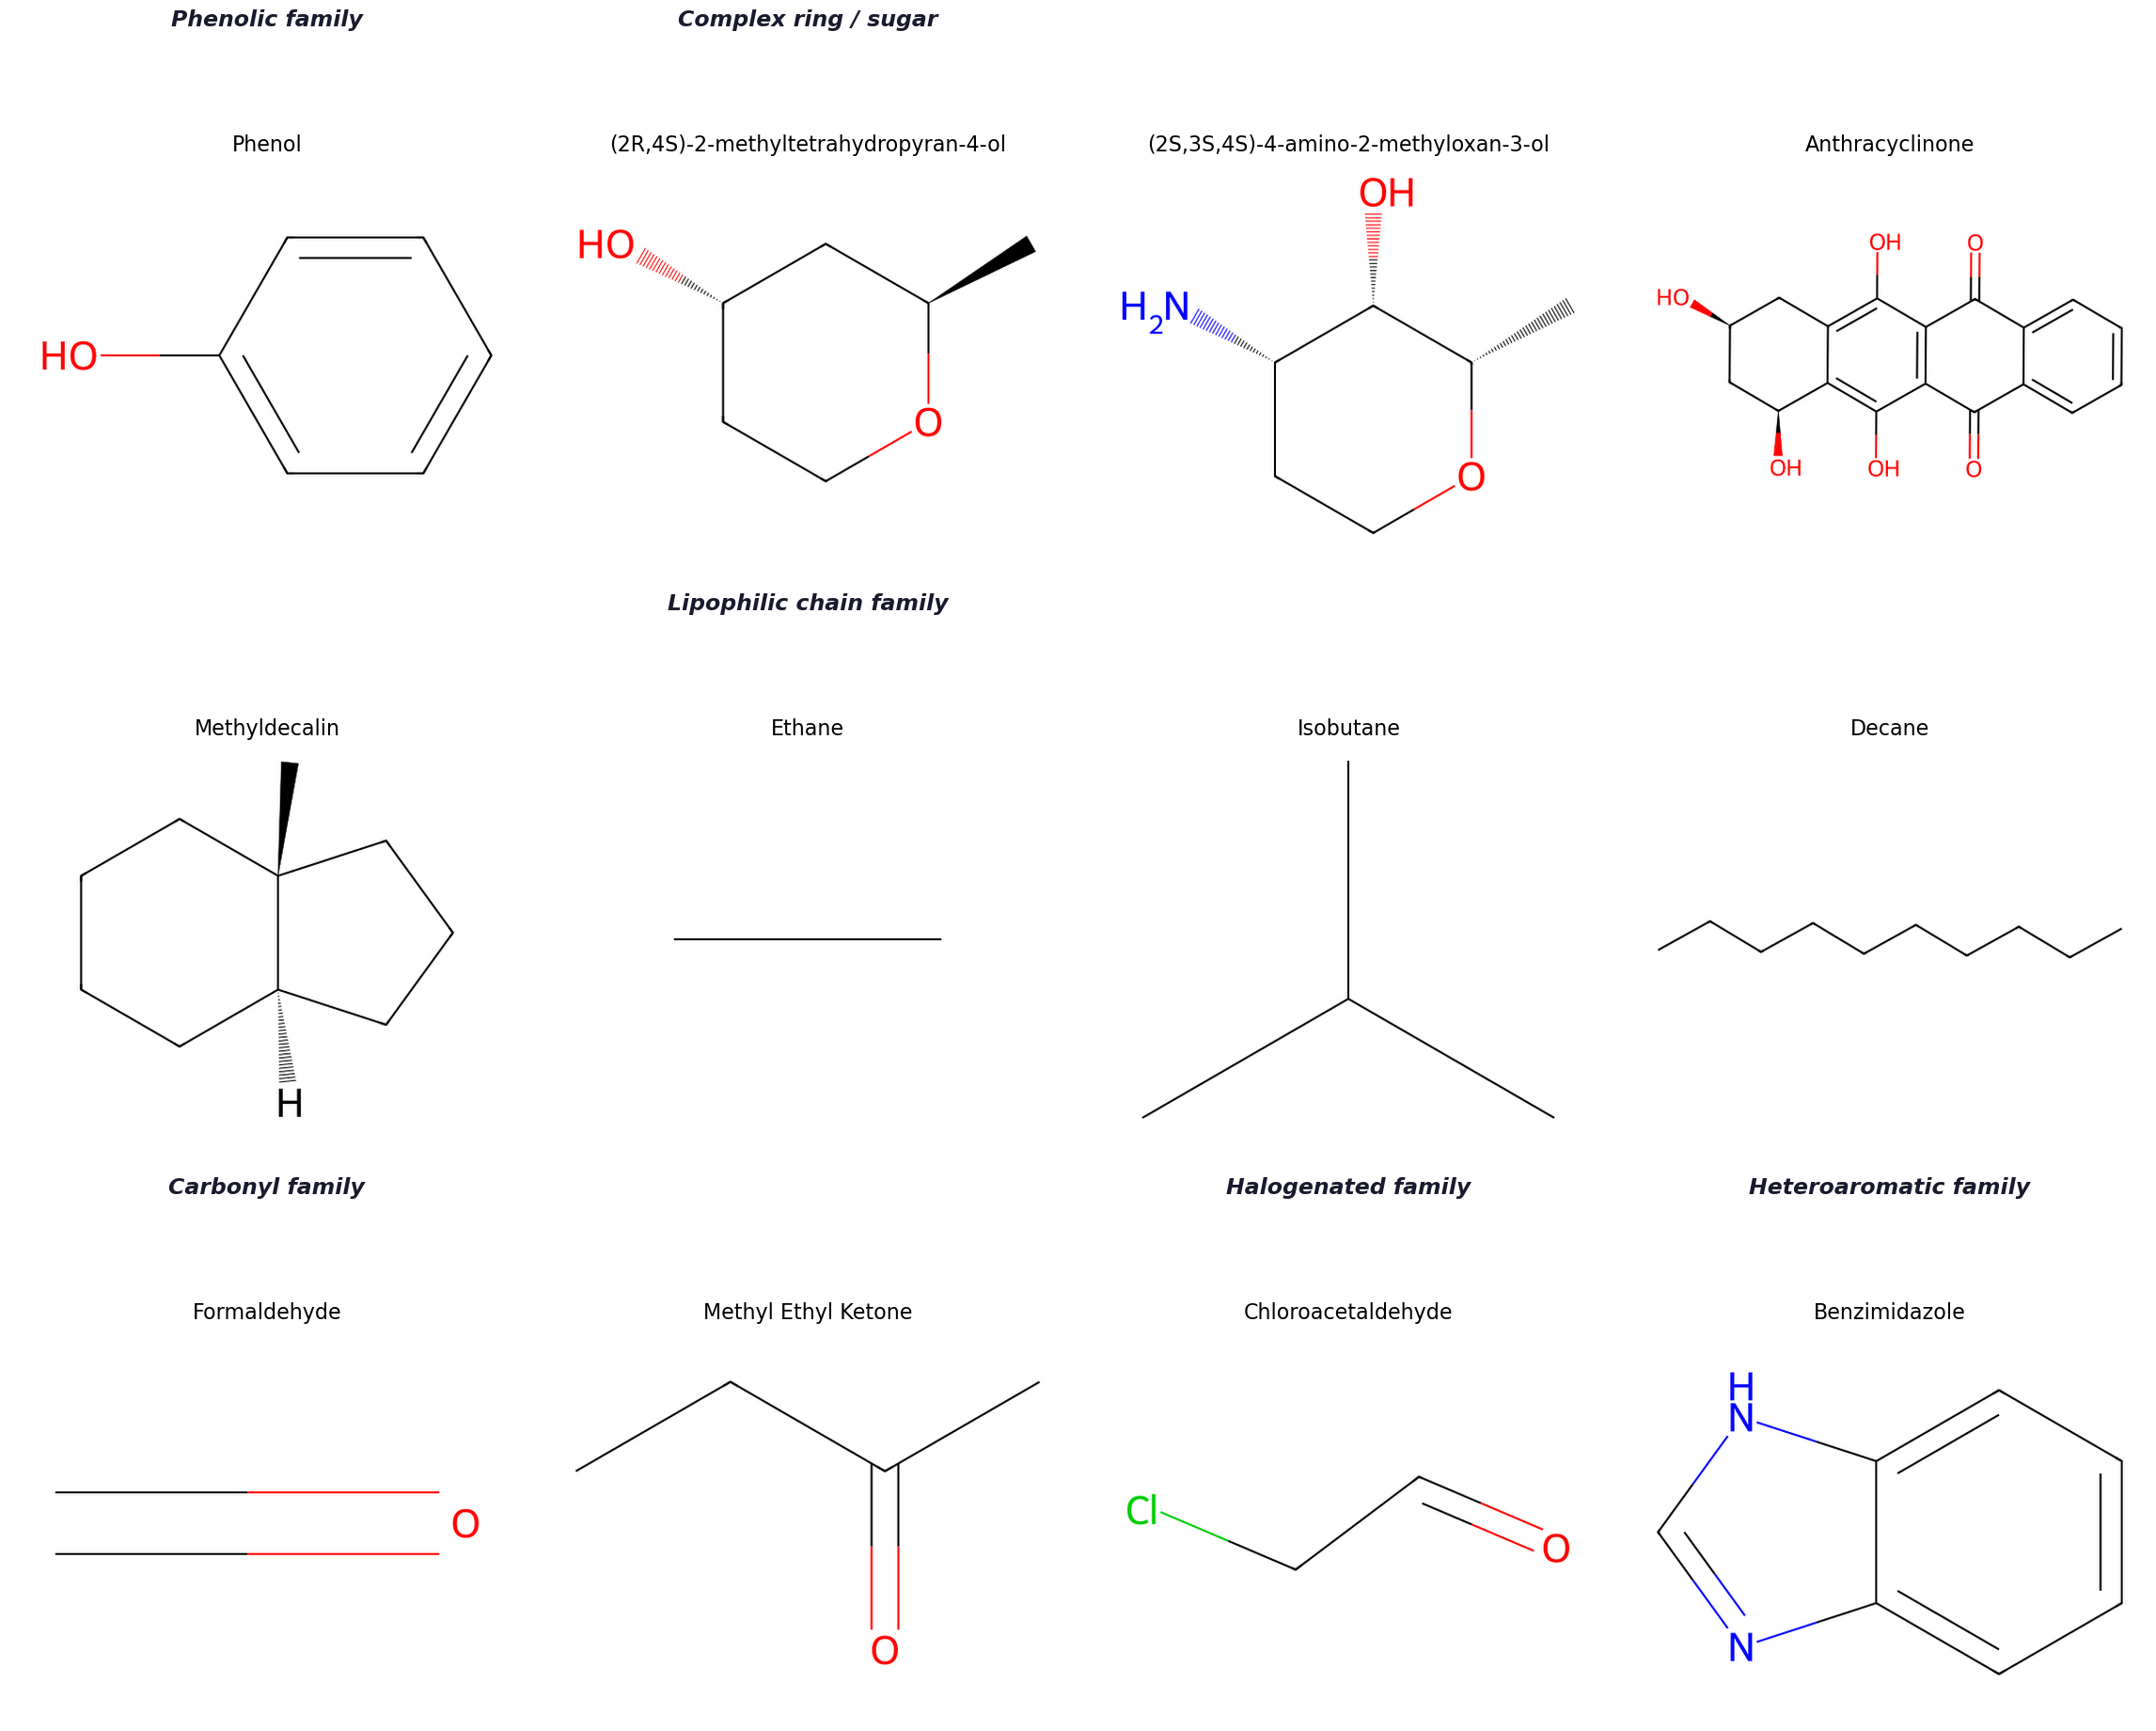

Saved -> /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_mito_mito_only_vs_both_inactive.png


In [48]:
# ── Analysis 3: Mito Active / Viability Inactive (680) vs Both Inactive (3,196)
enrich_a3 = run_analysis(
    df_mito_only, df_both_inactive,
    label_a='mito_only', label_b='both_inactive',
    fig_fname='fig_mito_mito_only_vs_both_inactive.png',
    top_n=12, min_count=3, fdr_alpha=0.05
)